# Driven Kitaev chain

This notebook simulates a finite, open Kitaev chain whose chemical potential is periodically driven. The state starts in the instantaneous ground state and is evolved with the time-dependent Schrödinger equation. We then measure the departure from the instantaneous ground state.

We use units with $\hbar = 1$. The many-body Hilbert-space dimension is $2^N$, so the exact calculation is intended for relatively small chains.

## 1. Numerical tools

The calculation uses sparse matrices because the fermionic operators act on a many-body Hilbert space. The time evolution is integrated with SciPy's high-order explicit solver.

In [1]:
import numpy as np

from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh
from scipy.integrate import solve_ivp
from scipy.linalg import polar

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from concurrent.futures import ThreadPoolExecutor

In [2]:
import time
from concurrent.futures import ThreadPoolExecutor
from functools import wraps
from tqdm import tqdm


def with_progress(desc="Processing"):
    """Decorator to run a function in a background thread while animating

    a progress spinner and reporting elapsed time.
    """

    def decorator(func):
        @wraps(func)
        def wrapper(*args, **kwargs):
            start_time = time.perf_counter()

            # Run target function in a separate thread
            with ThreadPoolExecutor(max_workers=1) as executor:
                future = executor.submit(func, *args, **kwargs)

                # Animate a progress bar while the function runs
                with tqdm(
                    desc=desc,
                    bar_format="{desc}: {elapsed} elapsed | {bar} |",
                    leave=True,
                ) as pbar:
                    while not future.done():
                        time.sleep(0.1)
                        pbar.update(1)

                result = future.result()

            elapsed = time.perf_counter() - start_time
            print(f"✓ '{func.__name__}' completed in {elapsed:.2f} seconds.")
            return result

        return wrapper

    return decorator

## 2. Kitaev-chain Hamiltonian

The open-chain Hamiltonian is

$$
H_0 = -\mu\sum_{j=0}^{N-1}\left(c_j^\dagger c_j - \frac12\right)
- t\sum_{j=0}^{N-2}\left(c_j^\dagger c_{j+1}+c_{j+1}^\dagger c_j\right)
+ \Delta\sum_{j=0}^{N-2}\left(c_jc_{j+1}+c_{j+1}^\dagger c_j^\dagger\right).
$$

Since the Hamiltonian is quadratic, we can express it in the Nambu basis:
$$
H_0 = \frac{1}{2}\Psi^\dagger \mathcal{H}_{BdG} \Psi,
$$
where
$$
\Psi = \begin{pmatrix}
c_1 \\ c_2 \\ \vdots \\ c_N \\
c_1^\dagger \\ c_2^\dagger \\ \vdots \\ c_N^\dagger
\end{pmatrix}\quad\text{and}\quad
\mathcal{H}_{BdG} = \left(\begin{array}{ccccc|ccccc}
-\mu    & -t      &        &         &        & 0       & -\Delta &         &        &         \\
-t      & -\mu    & -t     &         &        & \Delta  & 0       & -\Delta &        &         \\
        & -t      & -\mu   & \ddots  &        &         & \Delta  & 0       & \ddots &         \\
        &         & \ddots & \ddots  & -t     &         &         & \ddots  & \ddots & -\Delta \\
        &         &        & -t      & -\mu   &         &         &         & \Delta & 0       \\
\hline
0       & \Delta  &        &         &        & \mu     & t       &         &        &         \\
-\Delta & 0       & \Delta &         &        & -t      & \mu     & t       &        &         \\
        & -\Delta & 0      & \ddots  &        &         & -t      & \mu     & \ddots &         \\
        &         & \ddots & \ddots  & \Delta &         &         & \ddots  & \ddots & t       \\
        &         &        & -\Delta & 0      &         &         &         & -t     & \mu
\end{array}\right).
$$

The total number operator is given by
$$
\hat{N}
= \sum_j \left(c_j^\dagger c_j - \frac{1}{2}\right)
= \frac{1}{2} \sum_j \left(c_j^\dagger c_j - c_j c_j^\dagger\right)
= \Psi^\dagger \left(\begin{array}{c|c}
-\frac{I}{2} & \\
\hline
& \frac{I}{2}
\end{array}\right) \Psi.
$$

In [3]:
def build_kitaev_chain(N, mu, t_hop, delta=None):
    """Build the static Kitaev Hamiltonian and total number operator."""
    if delta is None:
        delta = t_hop

    if N < 2:
        raise ValueError("N must be at least 2.")

    A = np.zeros((N, N), dtype=np.complex128)
    B = np.zeros((N, N), dtype=np.complex128)
    for j in range(N):
        A[j, j] = -mu
    for j in range(N - 1):
        A[j, j + 1] = -t_hop
        A[j + 1, j] = -t_hop
        B[j, j + 1] = -delta
        B[j + 1, j] = delta
    
    H0 = np.block([[A, B], [-np.conj(B), -np.conj(A)]])
    N_op = np.diag(np.concatenate([
        -0.5 * np.ones(N, dtype=np.complex128),
        0.5 * np.ones(N, dtype=np.complex128),
    ]))

    return H0, N_op

build_kitaev_chain(2, 0.1, 0.2, 0.3)

(array([[-0.1+0.j, -0.2+0.j,  0. +0.j, -0.3+0.j],
        [-0.2+0.j, -0.1+0.j,  0.3+0.j,  0. +0.j],
        [-0. +0.j,  0.3+0.j,  0.1+0.j,  0.2+0.j],
        [-0.3+0.j, -0. +0.j,  0.2+0.j,  0.1+0.j]]),
 array([[-0.5+0.j,  0. +0.j,  0. +0.j,  0. +0.j],
        [ 0. +0.j, -0.5+0.j,  0. +0.j,  0. +0.j],
        [ 0. +0.j,  0. +0.j,  0.5+0.j,  0. +0.j],
        [ 0. +0.j,  0. +0.j,  0. +0.j,  0.5+0.j]]))

# 3. Validation of Topological Phase

In the thermodynamic limit $N\rightarrow\infty$, there is a phase transition at $|\mu|=2|t|$.

The topological phase is found at $|\mu| < 2|t|$, where there exist two Majorana zero modes, each localized at each boundary.

The code below sweeps $\mu$ from 0.0 to 3.0, plotting the two eigenvalues closest to zero.
The corresponding wave functions are also plotted.

In [4]:
def plot_topological_mode_diagnostics(param_values, energies_0, energies_1, 
                                     densities_0, densities_1, 
                                     param_name=r"$\mu$ / $t$"):
    """
    param_values: 1D array of parameter sweep (length M)
    energies_0, energies_1: 1D arrays of eigenvalues for modes 0 and 1 (length M)
    densities_0, densities_1: 2D arrays of shape (N_sites, M)
    """
    N_sites, M = densities_0.shape
    sites = np.arange(1, N_sites + 1)
    
    fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True, 
                             gridspec_kw={'height_ratios': [1, 1.2, 1.2]})
    
    # -------------------------------------------------------------
    # Panel 1: Energy Eigenvalues (Zero-mode Check)
    # -------------------------------------------------------------
    ax0 = axes[0]
    ax0.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax0.plot(param_values, energies_0, label=r"$E_0$", color="tab:blue", lw=2)
    ax0.plot(param_values, energies_1, label=r"$E_1$", color="tab:red", linestyle=":", lw=2)
    ax0.set_ylabel("Energy")
    ax0.set_title("Low-Energy Spectrum & Spatial Wavefunction Localization", fontsize=13)
    ax0.legend(loc="upper right", frameon=True)
    ax0.grid(True, linestyle=":", alpha=0.5)

    # -------------------------------------------------------------
    # Panel 2: Mode 0 Probability Density Heatmap (Log Scale)
    # -------------------------------------------------------------
    ax1 = axes[1]
    # Log density highlights exponential edge decay against bulk background
    log_dens_0 = np.log10(np.clip(densities_0, 1e-5, 1.0))
    im1 = ax1.pcolormesh(param_values, sites, log_dens_0, 
                         shading="auto", cmap="magma")
    ax1.set_ylabel("Site Index $j$")
    ax1.set_title(r"Mode 0: $\log_{10}|\psi_0(j)|^2$", fontsize=11)
    cbar1 = fig.colorbar(im1, ax=ax1, orientation="vertical", pad=0.02)
    cbar1.set_label("Log Density")

    # -------------------------------------------------------------
    # Panel 3: Mode 1 Probability Density Heatmap (Log Scale)
    # -------------------------------------------------------------
    ax2 = axes[2]
    log_dens_1 = np.log10(np.clip(densities_1, 1e-5, 1.0))
    im2 = ax2.pcolormesh(param_values, sites, log_dens_1, 
                         shading="auto", cmap="magma")
    ax2.set_xlabel(param_name, fontsize=12)
    ax2.set_ylabel("Site Index $j$")
    ax2.set_title(r"Mode 1: $\log_{10}|\psi_1(j)|^2$", fontsize=11)
    cbar2 = fig.colorbar(im2, ax=ax2, orientation="vertical", pad=0.02)
    cbar2.set_label("Log Density")

    plt.tight_layout()
    plt.show()

Processing: 00:55 elapsed |                                                                 |

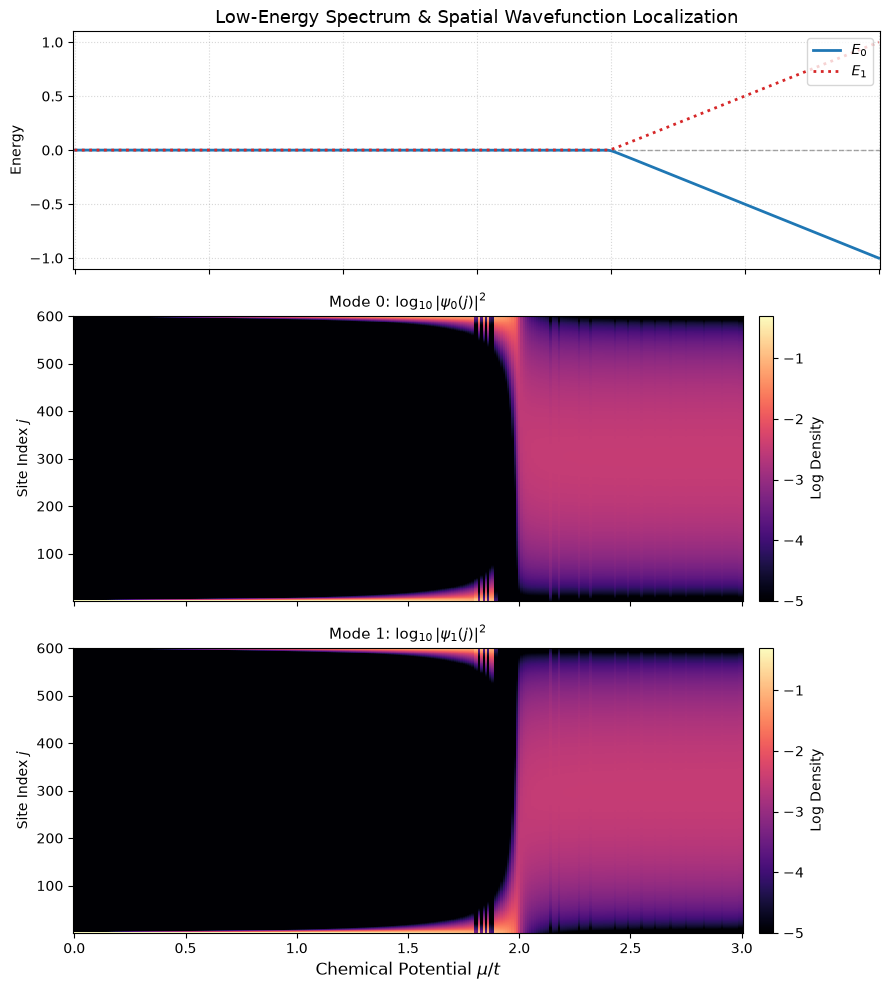

Processing: 00:55 elapsed |                                                                 |

✓ 'sweep_and_visualize' completed in 55.42 seconds.


In [5]:
@with_progress()
def sweep_and_visualize(N=50, t_hop=1.0, delta=1.0, mu_min=0.0, mu_max=3.0, num_points=301, decouple_edges=True):
    """
    Sweeps mu from mu_min to mu_max and runs the diagnostics plot.
    Kitaev transition occurs at |mu| = 2*t_hop (= 2.0 here).
    """
    mu_values = np.linspace(mu_min, mu_max, num_points)
    
    energies_0 = np.zeros(num_points)
    energies_1 = np.zeros(num_points)
    
    # 2D arrays storing spatial density per site (rows) vs parameter mu (cols)
    densities_0 = np.zeros((N, num_points))
    densities_1 = np.zeros((N, num_points))
    
    for idx, mu in enumerate(mu_values):
        H_bdg, _ = build_kitaev_chain(N=N, mu=mu, t_hop=t_hop, delta=delta)
        
        # Diagonalize: eigh sorts eigenvalues in ascending order
        # First N eigenvalues are negative (-E_N, ..., -E_1)
        # Next N eigenvalues are positive (+E_1, ..., +E_N)
        eigenvalues, eigenvectors = np.linalg.eigh(H_bdg)
        
        # The lowest two non-negative modes are indices N and N+1
        E0 = eigenvalues[N - 1]
        E1 = eigenvalues[N]
        psi0 = eigenvectors[:, N - 1]  # Shape (2N,)
        psi1 = eigenvectors[:, N    ]  # Shape (2N,)
        
        energies_0[idx] = E0
        energies_1[idx] = E1
        
        if decouple_edges and E0 < 1e-4:
            # Below the bulk gap, psi0 and psi1 are symmetric/antisymmetric linear 
            # combinations of both edge Majoranas. Rotating by 45 degrees decouples them 
            # into individual left-edge (gamma_L) and right-edge (gamma_R) modes:
            mode_L = (psi0 + psi1) / np.sqrt(2)
            mode_R = (psi0 - psi1) / (1j * np.sqrt(2))
        else:
            mode_L = psi0
            mode_R = psi1
            
        # Probability density at site j: |u_j|^2 + |v_j|^2
        # u components are elements 0 to N-1; v components are elements N to 2N-1
        u_L, v_L = mode_L[:N], mode_L[N:]
        u_R, v_R = mode_R[:N], mode_R[N:]
        
        densities_0[:, idx] = np.abs(u_L)**2 + np.abs(v_L)**2
        densities_1[:, idx] = np.abs(u_R)**2 + np.abs(v_R)**2

    plot_topological_mode_diagnostics(
        param_values=mu_values,
        energies_0=energies_0,
        energies_1=energies_1,
        densities_0=densities_0,
        densities_1=densities_1,
        param_name=r"Chemical Potential $\mu / t$"
    )

# N=50 is fast (< 1 second) and clearly separates edge modes from bulk continuum
sweep_and_visualize(N=600, t_hop=1.0, delta=1.0, mu_min=0.0, mu_max=3.0, num_points=301)

As we can see, the behavior changes quite abruptly near $\mu=2.0$.
The eigenvalues deviate from zero above that point, and the wavefunctions are supported by the bulk of the chain rather than being localized at each boundary.

## 4. Periodic drive and Floquet modes

The chemical potential is modulated as

$$
\mu(t)=\mu+A\cos(\omega t).
$$

Therefore, since the chemical-potential contribution is $-\mu\hat N$, the driven Hamiltonian can be written as

$$
H(t)=H_0-A\cos(\omega t)\,\hat N.
$$

Since the modulation is periodic, Floquet theory tells us that we can look at the one-period Floquet propagator:
$$
\mathcal{U}_F = \exp\left(-i\mathcal{T}\int_0^{\frac{2\pi}{\omega}} dt H(t)\right).
$$
Eigenvalues of this unitary operator are written as $e^{-i\varepsilon \frac{2\pi}{\omega}}$,
and $\varepsilon$ is called the quasienergy the corresponding mode.
Most prominent modes are the 0- and $\pi$-modes, with quasienergies 0 and $\pm\frac{\omega}{2}$.

In [6]:
def compute_U_F(H0_bdg, V_drive, A_drive, omega, dim):
    """Integrates the 2N x 2N unitary evolution operator over one period Td."""
    Td = 2.0 * np.pi / omega

    def rhs(t, y):
        W = y.reshape((dim, dim))
        H_t = H0_bdg + (A_drive * np.cos(omega * t)) * V_drive
        dW_dt = -1j * (H_t @ W)
        return dW_dt.ravel()

    y0 = np.eye(dim, dtype=np.complex128).ravel()
    sol = solve_ivp(rhs, (0.0, Td), y0, method="DOP853", rtol=1e-8, atol=1e-10)
    
    W_final = sol.y[:, -1].reshape((dim, dim))
    # Polar decomposition guarantees exact unitarity (removes numerical ODE drift)
    U_F, _ = polar(W_final)
    return U_F

In [7]:
@with_progress()
def sweep_frequency(N=80, mu=0.5, t_hop=1.0, delta=1.0, A_drive=0.6,
                    omega_min=0.1, omega_max=4.5, num_omega=120):
    dim = 2 * N
    H0_bdg, V_drive = build_kitaev_chain(N, mu, t_hop, delta)
    omegas = np.linspace(omega_min, omega_max, num_omega)
    
    quasienergies = np.zeros((dim, num_omega))
    phases = np.zeros((dim, num_omega))
    
    for idx, w in enumerate(omegas):
        Td = 2.0 * np.pi / w
        U_F = compute_U_F(H0_bdg, V_drive, A_drive, w, dim)
        
        # Eigenvalues of U_F are exp(-i * epsilon * Td)
        eigenvalues = np.linalg.eigvals(U_F)
        phase = np.angle(eigenvalues)  # in (-pi, pi]
        
        # Sort values for clean plotting
        phases[:, idx] = np.sort(phase)
        quasienergies[:, idx] = np.sort(phase / Td)

    # -----------------------------------------------------------------
    # Plotting
    # -----------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))

    # Panel 1: Quasienergy epsilon in [-omega/2, omega/2]
    ax1 = axes[0]
    for m in range(dim):
        ax1.scatter(omegas, quasienergies[m, :], s=1.0, color="black", alpha=0.6)
    
    # Boundary zones +- omega / 2
    ax1.plot(omegas, 0.5 * omegas, "r--", lw=1.2, label=r"$\pm \omega / 2$ (Zone boundary)")
    ax1.plot(omegas, -0.5 * omegas, "r--", lw=1.2)
    ax1.axhline(0, color="blue", linestyle=":", lw=1.2, label=r"$\varepsilon = 0$")
    ax1.set_xlabel(r"Drive Frequency $\omega / t$", fontsize=12)
    ax1.set_ylabel(r"Quasienergy $\varepsilon$", fontsize=12)
    ax1.set_title(r"Floquet Spectrum ($\varepsilon$ vs $\omega$)", fontsize=13)
    ax1.set_ylim(-0.55 * omega_max, 0.55 * omega_max)
    ax1.legend(loc="upper left")
    ax1.grid(True, linestyle=":", alpha=0.5)

    # Panel 2: Normalized Floquet Phase theta in [-pi, pi]
    ax2 = axes[1]
    for m in range(dim):
        ax2.scatter(omegas, phases[m, :], s=1.0, color="black", alpha=0.6)
        
    ax2.axhline(0, color="blue", linestyle=":", lw=1.5, label=r"$0$-modes ($\theta=0$)")
    ax2.axhline(np.pi, color="red", linestyle="--", lw=1.5, label=r"$\pi$-modes ($\theta=\pm\pi$)")
    ax2.axhline(-np.pi, color="red", linestyle="--", lw=1.5)
    ax2.set_xlabel(r"Drive Frequency $\omega / t$", fontsize=12)
    ax2.set_ylabel(r"Floquet Phase $\theta = \varepsilon T_d$", fontsize=12)
    ax2.set_title(r"Normalized Floquet Phase ($\theta$ vs $\omega$)", fontsize=13)
    ax2.set_ylim(-np.pi - 0.2, np.pi + 0.2)
    ax2.legend(loc="upper right")
    ax2.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    plt.show()

Processing: 00:13 elapsed |                                                                 |

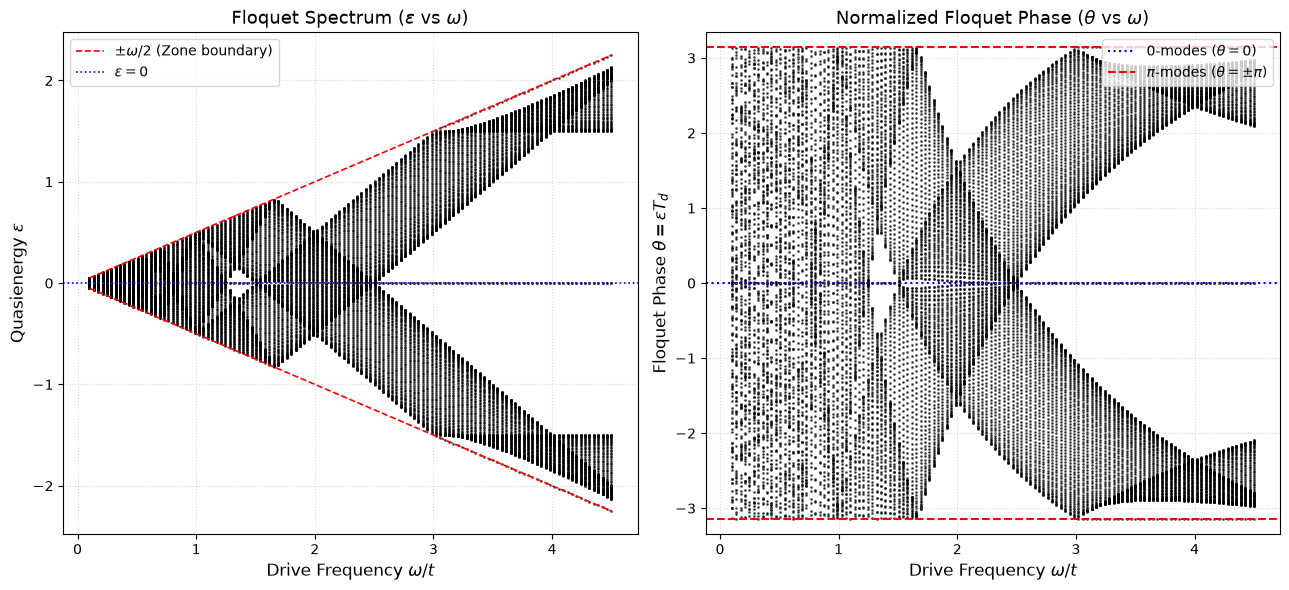

Processing: 00:13 elapsed |                                                                 |

✓ 'sweep_frequency' completed in 13.16 seconds.


In [8]:
sweep_frequency()

In [9]:
def evaluate_single_point(args):
    """
    Worker function executed in parallel.
    Computes U_F and returns the discrete phase index for given (omega, mu).
    """
    w, mu, N, t_hop, delta, A_drive, Lb, phase_tol, weight_thresh = args
    dim = 2 * N
    Td = 2.0 * np.pi / w
    H0_bdg, V_drive = build_kitaev_chain(N, mu, t_hop, delta)
    U_F = compute_U_F(H0_bdg, V_drive, A_drive, w, dim)
    
    evals, evecs = np.linalg.eig(U_F)
    phases = np.angle(evals)  # theta = epsilon * Td in (-pi, pi]
    
    # 1. 0-mode check (theta ~ 0)
    idx_0 = np.argmin(np.abs(phases))
    is_zero_energy = np.abs(phases[idx_0]) < phase_tol
    
    # 2. pi-mode check (|theta| ~ pi)
    diff_pi = np.abs(np.abs(phases) - np.pi)
    idx_pi = np.argmin(diff_pi)
    is_pi_energy = diff_pi[idx_pi] < phase_tol
    
    # Boundary localization weight over Lb boundary sites
    def calc_edge_weight(vec):
        prob = np.abs(vec[:N])**2 + np.abs(vec[N:])**2
        return np.sum(prob[:Lb]) + np.sum(prob[-Lb:])
    
    w0 = calc_edge_weight(evecs[:, idx_0]) if is_zero_energy else 0.0
    wpi = calc_edge_weight(evecs[:, idx_pi]) if is_pi_energy else 0.0
    
    has_0 = int(w0 > weight_thresh)
    has_pi = int(wpi > weight_thresh)
    
    # Phase coding:
    # 0 = Trivial
    # 1 = 0-mode only
    # 2 = pi-mode only
    # 3 = Both (0 and pi modes coexist)
    return has_0 + 2 * has_pi

In [10]:
@with_progress()
def compute_phase_diagram(
    N=60,                  # N = 50-80 provides sharp boundaries while running rapidly
    t_hop=1.0,
    delta=1.0,
    A_drive=0.6,
    omega_min=1.0,
    omega_max=4.5,
    num_omega=60,
    mu_min=0.0,
    mu_max=3.0,
    num_mu=60,
    Lb=5,
    phase_tol=0.08,        # tolerance around theta = 0 or pi
    weight_thresh=0.60,    # minimum boundary localization weight
    max_workers=None       # None defaults to all available CPU cores
):
    omegas = np.linspace(omega_min, omega_max, num_omega)
    mus = np.linspace(mu_min, mu_max, num_mu)
    
    # Prepare parameter list for parallel evaluation
    # Row index: mu, Column index: omega
    tasks = []
    for mu in mus:
        for w in omegas:
            tasks.append((w, mu, N, t_hop, delta, A_drive, Lb, phase_tol, weight_thresh))
            
    print(f"Sweeping grid: {num_mu} (mu) x {num_omega} (omega) = {len(tasks)} points using multiprocessing...")
    start_time = time.time()
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        results = list(executor.map(evaluate_single_point, tasks))
        
    elapsed = time.time() - start_time
    print(f"Sweep completed in {elapsed:.1f} seconds ({elapsed / len(tasks) * 1000:.2f} ms per point).")
    
    # Reshape results into 2D grid matrix
    phase_map = np.array(results).reshape((num_mu, num_omega))
    
    # -------------------------------------------------------------
    # Plotting Phase Map
    # -------------------------------------------------------------
    # Discrete colormap:
    # 0: Slate grey (Trivial)
    # 1: Tab:blue (0-mode only)
    # 2: Tab:red (pi-mode only)
    # 3: Tab:purple (0-mode and pi-mode coexistence)
    cmap = ListedColormap(["#3d3d3d", "#1f77b4", "#d62728", "#9467bd"])
    
    plt.figure(figsize=(9, 7))
    # Note: imshow with origin='lower' places mus[0] at the bottom
    im = plt.imshow(
        phase_map,
        origin="lower",
        extent=[omega_min, omega_max, mu_min, mu_max],
        aspect="auto",
        cmap=cmap,
        vmin=-0.5,
        vmax=3.5,
        interpolation="nearest"
    )
    
    # High-frequency analytical boundary: mu_c = 2*t
    plt.axhline(2.0 * t_hop, color="white", linestyle="--", lw=1.5, label=r"Static $\mu_c = 2t$")
    
    # Resonant multi-photon threshold: omega = 2 * Delta_bulk(mu) = 2 * 2|t - mu|
    # When omega <= 4|t - mu|, single-photon absorption into bulk band occurs
    w_res = np.linspace(omega_min, omega_max, 200)
    mu_res_lower = np.clip(t_hop - 0.25 * w_res, 0.0, None)
    plt.plot(w_res, mu_res_lower, color="cyan", linestyle=":", lw=1.5, label=r"Single-Photon Bulk Resonance")
    
    plt.xlabel(r"Drive Frequency $\omega / t$", fontsize=13)
    plt.ylabel(r"Chemical Potential $\mu / t$", fontsize=13)
    plt.title(f"Floquet Phase Diagram ($N={N}, A={A_drive}, \Delta={delta}$)", fontsize=14)
    
    # Custom Legend for the discrete phases
    legend_elements = [
        Patch(facecolor="#3d3d3d", edgecolor="w", label="Trivial (No Edge Modes)"),
        Patch(facecolor="#1f77b4", edgecolor="w", label=r"Floquet $0$-Mode Only"),
        Patch(facecolor="#d62728", edgecolor="w", label=r"Floquet $\pi$-Mode Only"),
        Patch(facecolor="#9467bd", edgecolor="w", label=r"Coexistence ($0$ and $\pi$)"),
    ]
    plt.legend(handles=legend_elements, loc="upper right", framealpha=0.9)
    plt.grid(color="white", linestyle=":", alpha=0.2)
    plt.tight_layout()
    plt.show()

    return omegas, mus, phase_map

Sweeping grid: 10 (mu) x 10 (omega) = 100 points using multiprocessing...


Processing: 59:52 elapsed |                                                                 |

Sweep completed in 3592.3 seconds (35922.57 ms per point).


Processing: 59:52 elapsed |                                                                 |

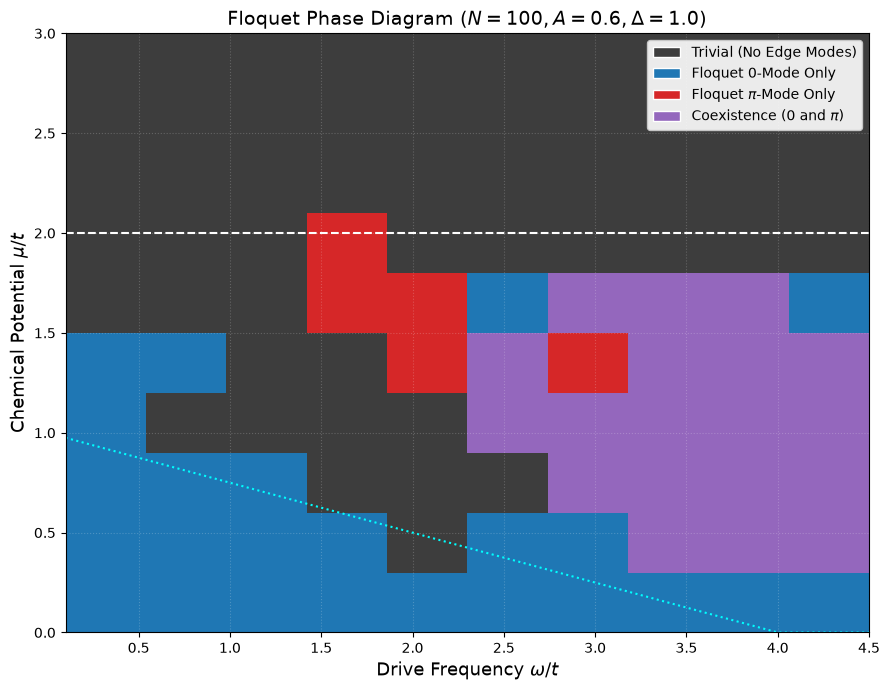

Processing: 59:52 elapsed |                                                                 |

✓ 'compute_phase_diagram' completed in 3590.74 seconds.


In [12]:
omegas, mus, phase_map = compute_phase_diagram(
    N=100,
    t_hop=1.0,
    delta=1.0,
    A_drive=0.6,
    omega_min=0.1,
    omega_max=4.5,
    num_omega=10,
    mu_min=0.0,
    mu_max=3.0,
    num_mu=10,
)